# Theme Alpha Q2: LowVol Trend Walk-Forward Validation

Q1 asked whether LowVolTrend RiskParity is worth further study. Q2 asks a stricter question:

> If parameters are selected only from trailing data, does LowVolTrend remain useful in the next validation window?

This notebook tests walk-forward selection across a small parameter family rather than optimizing one full-sample setting.


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q2-lowvol-trend-walkforward")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2023-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0
REBALANCE_DAYS = 10
REBALANCE_ANCHOR = "2024-01-02"

BASELINE_ASSETS = ("510300.SS", "513100.SS", "518880.SS")
THEME_ASSETS = ("513100.SS", "512400.SS", "159995.SZ", "515880.SS", "518880.SS")
COMMON_SYMBOLS = tuple(dict.fromkeys(BASELINE_ASSETS + THEME_ASSETS))
SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "512400.SS": "有色金属ETF",
    "159995.SZ": "芯片ETF",
    "515880.SS": "通信ETF",
    "518880.SS": "黄金ETF",
}

MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
MA_WINDOWS = [60, 90, 120, 180, 200]
CAP_LEVELS = [0.45, 0.50, 0.55]

print(f"Output dir: {OUTPUT_DIR}")


Output dir: outputs/theme-alpha-q2-lowvol-trend-walkforward


## 1. Data Loading


In [2]:
def flatten_yfinance(df):
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df


def download_ohlc(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, progress=False, auto_adjust=False, threads=False)
    df = flatten_yfinance(df)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    keep = [c for c in ["Open", "High", "Low", "Close", "Adj Close", "Volume"] if c in df.columns]
    df = df[keep].copy()
    df.columns = [c.lower().replace(" ", "_") for c in df.columns]
    df.index = pd.to_datetime(df.index).tz_localize(None)
    return df.sort_index()

market = {symbol: download_ohlc(symbol) for symbol in COMMON_SYMBOLS}
availability = pd.DataFrame([
    {"symbol": s, "name": SYMBOL_NAMES[s], "first_date": market[s].index.min().date(), "last_date": market[s].index.max().date(), "rows": len(market[s])}
    for s in COMMON_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)

idx = None
for symbol in COMMON_SYMBOLS:
    cur = market[symbol]["close"].dropna().index
    idx = cur if idx is None else idx.intersection(cur)
idx = pd.DatetimeIndex(idx).sort_values()
close = pd.DataFrame({s: market[s]["close"].reindex(idx) for s in COMMON_SYMBOLS}).dropna()
high = pd.DataFrame({s: market[s]["high"].reindex(close.index) for s in COMMON_SYMBOLS})
low = pd.DataFrame({s: market[s]["low"].reindex(close.index) for s in COMMON_SYMBOLS})
returns = close.pct_change().fillna(0.0)
print(f"Common sample: {close.index.min().date()} to {close.index.max().date()}, rows={len(close)}")


,symbol,name,first_date,last_date,rows
0,510300.SS,沪深300ETF,2023-01-03,2026-06-23,837
1,513100.SS,纳指100ETF,2023-01-03,2026-06-23,838
2,518880.SS,黄金ETF,2023-01-03,2026-06-23,837
3,512400.SS,有色金属ETF,2023-01-03,2026-06-23,837
4,159995.SZ,芯片ETF,2023-01-03,2026-06-23,837
5,515880.SS,通信ETF,2023-01-03,2026-06-23,837


Common sample: 2023-01-03 to 2026-06-23, rows=837


## 2. Portfolio Helpers


In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def rebalance_dates(index, every=REBALANCE_DAYS, anchor=REBALANCE_ANCHOR):
    idx = pd.DatetimeIndex(index)
    start = idx.searchsorted(pd.Timestamp(anchor))
    return set(pd.DatetimeIndex(idx[start::every]))


def risk_parity_weight(date, eligible, universe, vol_window=RP_VOL_WINDOW, cap=None):
    eligible = [sym for sym in eligible if sym in universe]
    if not eligible:
        return normalize_weights({}, universe)
    loc = close.index.get_loc(date)
    if loc < vol_window:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - vol_window + 1: loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    return apply_cap(raw, universe, cap)


def equal_weight(eligible, universe):
    eligible = [sym for sym in eligible if sym in universe]
    if not eligible:
        return normalize_weights({}, universe)
    return normalize_weights({sym: 1.0 / len(eligible) for sym in eligible}, universe)


def all_assets(universe):
    return lambda _date: list(universe)


def low_vol_trend_selector(universe, ma_window, mom_window=MOM_WINDOW, vol_window=VOL_WINDOW, top_n=TOP_N):
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(ma_window, mom_window, vol_window)
        if loc < warmup:
            return []
        symbols = list(universe)
        price = close.iloc[loc][symbols]
        ma = close.iloc[loc - ma_window + 1: loc + 1][symbols].mean()
        mom = price / close.iloc[loc - mom_window][symbols] - 1.0
        vols = returns.iloc[loc - vol_window + 1: loc + 1][symbols].std(ddof=1)
        eligible = price.index[(price > ma) & (mom > 0)].tolist()
        if not eligible:
            return []
        return vols[eligible].sort_values().head(top_n).index.tolist()
    return select


def build_weights(universe, selector, allocator):
    rdates = rebalance_dates(close.index)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in rdates:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def turnover_from_signal_weights(signal_weights, universe):
    actual = signal_weights[list(universe) + ["CASH"]].shift(1).fillna(0.0)
    return 0.5 * actual.diff().abs().sum(axis=1).fillna(actual.abs().sum(axis=1))


def backtest_from_weights(name, universe, signal_weights, cost_bps=0.0):
    asset_weights = signal_weights[list(universe)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(universe)]).sum(axis=1)
    turnover = turnover_from_signal_weights(signal_weights, universe)
    net = gross - turnover * (cost_bps / 10000.0)
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {"name": name, "universe": tuple(universe), "weights": signal_weights, "returns": net, "gross_returns": gross, "turnover": turnover, "nav": nav.rename(name)}


def run_strategy(name, universe, selector, allocator, cost_bps=0.0):
    w = build_weights(universe, selector, allocator)
    return backtest_from_weights(name, universe, w, cost_bps)


def static_mix(name, weights_map, cost_bps=0.0):
    universe = tuple(weights_map.keys())
    total = sum(weights_map.values())
    w = pd.DataFrame(0.0, index=close.index, columns=list(universe) + ["CASH"])
    for sym, val in weights_map.items():
        w[sym] = val / total
    return backtest_from_weights(name, universe, w, cost_bps)


def metrics_row(name, r, weights=None, turnover=None):
    r = r.dropna()
    if len(r) == 0:
        return {"策略": name}
    nav = (1.0 + r).cumprod() * INITIAL_NAV
    total = nav.iloc[-1] / INITIAL_NAV - 1.0
    ann = (1.0 + total) ** (TRADING_DAYS / len(r)) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS) if len(r) > 1 else np.nan
    dd = nav / nav.cummax() - 1.0
    mdd = dd.min()
    sharpe = ann / vol if pd.notna(vol) and vol > 0 else np.nan
    calmar = ann / abs(mdd) if pd.notna(mdd) and mdd < 0 else np.nan
    row = {"策略": name, "累计收益": total, "年化收益": ann, "年化波动": vol, "最大回撤": mdd, "夏普": sharpe, "卡玛": calmar}
    if turnover is not None:
        t = turnover.reindex(r.index).fillna(0.0)
        row["年化换手"] = t.mean() * TRADING_DAYS
        row["总换手"] = t.sum()
    if weights is not None:
        w = weights.reindex(r.index).ffill().fillna(0.0)
        asset_cols = [c for c in w.columns if c != "CASH"]
        row["平均现金"] = w["CASH"].mean() if "CASH" in w else 0.0
        row["平均最大单资产权重"] = w[asset_cols].max(axis=1).mean() if asset_cols else np.nan
        row["当前最大单资产权重"] = w[asset_cols].iloc[-1].max() if asset_cols else np.nan
    return row


def slice_series(s, start, end=None):
    out = s.loc[pd.Timestamp(start):]
    if end is not None:
        out = out.loc[:pd.Timestamp(end)]
    return out.dropna()


def period_metric(r, metric="夏普"):
    row = metrics_row("tmp", r)
    val = row.get(metric, np.nan)
    return -np.inf if pd.isna(val) else val


## 3. Static Parameter Grid

Q2 does not search a huge grid. It asks whether a small cap45/50/55 family and nearby trend windows form a stable platform.


In [4]:
def variant_name(ma, cap):
    return f"LVT_MA{ma}_cap{int(cap*100)}"

variant_ports = {}
for ma in MA_WINDOWS:
    for cap in CAP_LEVELS:
        name = variant_name(ma, cap)
        variant_ports[name] = run_strategy(
            name,
            THEME_ASSETS,
            low_vol_trend_selector(THEME_ASSETS, ma_window=ma),
            lambda date, eligible, cap=cap: risk_parity_weight(date, eligible, THEME_ASSETS, RP_VOL_WINDOW, cap),
            cost_bps=0.0,
        )

benchmarks = {
    "原三资产RiskParity": run_strategy("原三资产RiskParity", BASELINE_ASSETS, all_assets(BASELINE_ASSETS), lambda d, e: risk_parity_weight(d, e, BASELINE_ASSETS), 0.0),
    "主题RiskParity": run_strategy("主题RiskParity", THEME_ASSETS, all_assets(THEME_ASSETS), lambda d, e: risk_parity_weight(d, e, THEME_ASSETS), 0.0),
    "主题等权": run_strategy("主题等权", THEME_ASSETS, all_assets(THEME_ASSETS), lambda d, e: equal_weight(e, THEME_ASSETS), 0.0),
    "纯纳指ETF": static_mix("纯纳指ETF", {"513100.SS": 1.0}, 0.0),
    "纯黄金ETF": static_mix("纯黄金ETF", {"518880.SS": 1.0}, 0.0),
    "60_40沪深300黄金": static_mix("60_40沪深300黄金", {"510300.SS": 0.6, "518880.SS": 0.4}, 0.0),
}

windows = {
    "2025_only": ("2025-01-01", "2025-12-31"),
    "2026_ytd": ("2026-01-01", None),
    "2025_to_date": ("2025-01-01", None),
}

static_tables = {}
for window_name, (start, end) in windows.items():
    rows = []
    for name, port in {**variant_ports, **benchmarks}.items():
        r = slice_series(port["returns"], start, end)
        if len(r) < 20:
            continue
        rows.append(metrics_row(name, r, port["weights"], port["turnover"]))
    df = pd.DataFrame(rows).set_index("策略").sort_values("夏普", ascending=False)
    static_tables[window_name] = df
    df.to_csv(OUTPUT_DIR / f"static_parameter_grid_{window_name}.csv", encoding="utf-8-sig")
    print()
    print(f"Static grid - {window_name}")
    display(df[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "年化换手", "平均现金", "平均最大单资产权重"]].round(4))



Static grid - 2025_only


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_MA60_cap55,0.7176,0.7565,-0.0685,4.5187,11.0498,5.3584,0.0000,0.4894
LVT_MA60_cap45,0.6938,0.7311,-0.0695,4.4669,10.5267,5.1497,0.0124,0.4404
LVT_MA60_cap50,0.6985,0.7361,-0.0731,4.3913,10.0709,5.2582,0.0000,0.4714
主题RiskParity,0.6245,0.6574,-0.1008,3.7143,6.5243,2.2635,0.0000,0.3353
LVT_MA120_cap55,0.5672,0.5965,-0.0685,3.7092,8.7137,6.1781,0.0000,0.4731
LVT_MA90_cap55,0.5515,0.5799,-0.0685,3.6251,8.4705,5.8532,0.0000,0.4751
LVT_MA120_cap50,0.5472,0.5754,-0.0731,3.5671,7.8719,5.9930,0.0000,0.4588
LVT_MA120_cap45,0.5321,0.5594,-0.0695,3.5633,8.0539,5.8000,0.0124,0.4331
LVT_MA180_cap55,0.5363,0.5638,-0.0685,3.4735,8.2358,5.4919,0.0000,0.4746



Static grid - 2026_ytd


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_MA60_cap45,0.2710,0.7235,-0.2521,2.0846,2.8697,9.1672,0.0991,0.4052
LVT_MA60_cap55,0.2714,0.7248,-0.2639,2.0771,2.7459,9.2696,0.0901,0.4537
LVT_MA60_cap50,0.2714,0.7248,-0.2630,2.0716,2.7562,9.3860,0.0901,0.4331
LVT_MA90_cap50,0.2256,0.5869,-0.2385,1.6334,2.4605,5.8288,0.0000,0.4558
LVT_MA90_cap55,0.2221,0.5768,-0.2385,1.6210,2.4179,5.9423,0.0000,0.4693
LVT_MA120_cap50,0.2216,0.5753,-0.2385,1.6063,2.4118,4.9297,0.0000,0.4600
LVT_MA200_cap50,0.2216,0.5753,-0.2385,1.6063,2.4118,4.9297,0.0000,0.4600
LVT_MA180_cap50,0.2216,0.5753,-0.2385,1.6063,2.4118,4.9297,0.0000,0.4600
LVT_MA90_cap45,0.2135,0.5517,-0.2396,1.5557,2.3024,5.5541,0.0180,0.4344



Static grid - 2025_to_date


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_MA60_cap55,1.1838,0.7464,-0.2639,3.1200,2.8280,6.5883,0.0283,0.4782
LVT_MA60_cap45,1.1528,0.7287,-0.2521,3.0797,2.8903,6.4130,0.0397,0.4293
LVT_MA60_cap50,1.1595,0.7326,-0.2630,3.0550,2.7856,6.5562,0.0283,0.4594
LVT_MA120_cap55,0.8978,0.5799,-0.2385,2.4316,2.4312,5.7855,0.0000,0.4749
LVT_MA90_cap55,0.8961,0.5789,-0.2385,2.4230,2.4269,5.8813,0.0000,0.4732
LVT_MA120_cap50,0.8901,0.5754,-0.2385,2.3910,2.4120,5.6586,0.0000,0.4592
LVT_MA90_cap50,0.8755,0.5666,-0.2385,2.3521,2.3755,5.6942,0.0000,0.4581
LVT_MA120_cap45,0.8429,0.5471,-0.2396,2.3467,2.2834,5.4307,0.0184,0.4338
LVT_MA180_cap55,0.8604,0.5577,-0.2385,2.3315,2.3378,5.3151,0.0000,0.4759


## 4. Walk-Forward Selection

At each validation step, parameters are selected only from trailing training-window returns. Then the selected variant's signal weights are used for the next validation window and re-costed as one stitched portfolio.


In [5]:
def composite_score(r):
    row = metrics_row("tmp", r)
    sharpe = row.get("夏普", np.nan)
    calmar = row.get("卡玛", np.nan)
    total = row.get("累计收益", np.nan)
    vals = [v for v in [sharpe, calmar, total] if pd.notna(v)]
    return sum(vals) if vals else -np.inf


def build_walkforward_weights(name, train_days, validate_days, rank_metric="夏普", start="2025-01-01", end=None):
    eval_index = close.loc[pd.Timestamp(start):].index
    if end is not None:
        eval_index = eval_index[eval_index <= pd.Timestamp(end)]
    start_pos = close.index.get_loc(eval_index[0])
    end_pos = close.index.get_loc(eval_index[-1])

    stitched = pd.DataFrame(0.0, index=close.index, columns=list(THEME_ASSETS) + ["CASH"])
    stitched["CASH"] = 1.0
    selection_rows = []
    pos = start_pos
    while pos <= end_pos:
        train_start = max(0, pos - train_days)
        train_idx = close.index[train_start:pos]
        if len(train_idx) < max(60, train_days // 2):
            pos += validate_days
            continue
        train_start_date = train_idx[0]
        train_end_date = train_idx[-1]
        scores = []
        for variant, port in variant_ports.items():
            tr = port["returns"].loc[train_start_date:train_end_date]
            if rank_metric == "composite":
                score = composite_score(tr)
            else:
                score = period_metric(tr, rank_metric)
            scores.append({"variant": variant, "score": score})
        score_df = pd.DataFrame(scores).sort_values(["score", "variant"], ascending=[False, True])
        selected = score_df.iloc[0]["variant"]
        val_end_pos = min(end_pos, pos + validate_days - 1)
        val_idx = close.index[pos: val_end_pos + 1]
        stitched.loc[val_idx, list(THEME_ASSETS) + ["CASH"]] = variant_ports[selected]["weights"].loc[val_idx, list(THEME_ASSETS) + ["CASH"]]
        ma = int(selected.split("_")[1].replace("MA", ""))
        cap = int(selected.split("_")[2].replace("cap", "")) / 100.0
        selection_rows.append({
            "wf_name": name,
            "train_days": train_days,
            "validate_days": validate_days,
            "rank_metric": rank_metric,
            "train_start": train_start_date,
            "train_end": train_end_date,
            "validate_start": val_idx[0],
            "validate_end": val_idx[-1],
            "selected_variant": selected,
            "selected_ma": ma,
            "selected_cap": cap,
            "selected_score": score_df.iloc[0]["score"],
        })
        pos += validate_days
    return stitched, pd.DataFrame(selection_rows)

wf_specs = [
    ("WF_6m_1m_sharpe", 126, 21, "夏普"),
    ("WF_12m_1m_sharpe", 252, 21, "夏普"),
    ("WF_12m_3m_sharpe", 252, 63, "夏普"),
    ("WF_12m_1m_calmar", 252, 21, "卡玛"),
    ("WF_12m_1m_composite", 252, 21, "composite"),
]

wf_weight_map = {}
selection_frames = []
for name, train_days, validate_days, metric in wf_specs:
    w, sel = build_walkforward_weights(name, train_days, validate_days, metric, start="2025-01-01")
    wf_weight_map[name] = w
    selection_frames.append(sel)
selection_history = pd.concat(selection_frames, ignore_index=True)
selection_history.to_csv(OUTPUT_DIR / "selection_history.csv", index=False, encoding="utf-8-sig")

selection_counts = selection_history.groupby(["wf_name", "selected_variant", "selected_ma", "selected_cap"]).size().reset_index(name="count")
selection_counts.to_csv(OUTPUT_DIR / "selection_counts.csv", index=False, encoding="utf-8-sig")
display(selection_counts.sort_values(["wf_name", "count"], ascending=[True, False]))


,wf_name,selected_variant,selected_ma,selected_cap,count
3,WF_12m_1m_calmar,LVT_MA60_cap55,60,0.55,7
0,WF_12m_1m_calmar,LVT_MA120_cap50,120,0.50,4
1,WF_12m_1m_calmar,LVT_MA120_cap55,120,0.55,3
2,WF_12m_1m_calmar,LVT_MA60_cap45,60,0.45,3
7,WF_12m_1m_composite,LVT_MA60_cap55,60,0.55,7
5,WF_12m_1m_composite,LVT_MA120_cap55,120,0.55,4
4,WF_12m_1m_composite,LVT_MA120_cap50,120,0.50,3
6,WF_12m_1m_composite,LVT_MA60_cap45,60,0.45,3
11,WF_12m_1m_sharpe,LVT_MA60_cap55,60,0.55,8
8,WF_12m_1m_sharpe,LVT_MA120_cap55,120,0.55,4


## 5. Walk-Forward Performance And Cost Sensitivity


In [6]:
def evaluate_walkforward(cost_bps=0.0, start="2025-01-01", end=None):
    wf_ports = {name: backtest_from_weights(name, THEME_ASSETS, w, cost_bps=cost_bps) for name, w in wf_weight_map.items()}
    static_focus = {
        "LVT_MA60_cap45": variant_ports["LVT_MA60_cap45"],
        "LVT_MA60_cap50": variant_ports["LVT_MA60_cap50"],
        "LVT_MA60_cap55": variant_ports["LVT_MA60_cap55"],
        "LVT_MA120_cap50": variant_ports["LVT_MA120_cap50"],
        "主题RiskParity": benchmarks["主题RiskParity"],
        "原三资产RiskParity": benchmarks["原三资产RiskParity"],
        "纯纳指ETF": benchmarks["纯纳指ETF"],
    }
    # Re-cost static strategies when cost_bps is nonzero.
    if cost_bps != 0:
        static_focus = {name: backtest_from_weights(name, port["universe"], port["weights"], cost_bps=cost_bps) for name, port in static_focus.items()}
    rows = []
    for name, port in {**wf_ports, **static_focus}.items():
        r = slice_series(port["returns"], start, end)
        rows.append(metrics_row(name, r, port["weights"], port["turnover"]))
    df = pd.DataFrame(rows).set_index("策略").sort_values("夏普", ascending=False)
    return df, {**wf_ports, **static_focus}

wf_tables = {}
for cost in [0, 10, 20]:
    df, ports = evaluate_walkforward(cost_bps=cost)
    wf_tables[cost] = df
    df.to_csv(OUTPUT_DIR / f"walkforward_summary_2025_to_date_cost{cost}bps.csv", encoding="utf-8-sig")
    if cost == 0:
        df.to_csv(OUTPUT_DIR / "walkforward_summary_2025_to_date.csv", encoding="utf-8-sig")
    print()
    print(f"Walk-forward summary, cost={cost}bps")
    display(df[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "年化换手", "平均现金", "平均最大单资产权重"]].round(4))

# Also export 2026 YTD comparison.
df_2026, ports_2026 = evaluate_walkforward(cost_bps=0, start="2026-01-01")
df_2026.to_csv(OUTPUT_DIR / "walkforward_summary_2026_ytd.csv", encoding="utf-8-sig")
print()
print("Walk-forward summary, 2026 YTD")
display(df_2026[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "年化换手", "平均现金", "平均最大单资产权重"]].round(4))



Walk-forward summary, cost=0bps


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_MA60_cap55,1.1838,0.7464,-0.2639,3.1200,2.8280,6.5883,0.0283,0.4782
LVT_MA60_cap45,1.1528,0.7287,-0.2521,3.0797,2.8903,6.4130,0.0397,0.4293
LVT_MA60_cap50,1.1595,0.7326,-0.2630,3.0550,2.7856,6.5562,0.0283,0.4594
WF_12m_1m_sharpe,1.1499,0.7271,-0.2524,3.0452,2.8802,7.3698,0.0312,0.4592
WF_12m_3m_sharpe,1.1117,0.7051,-0.2639,2.9341,2.6714,7.6866,0.0312,0.4648
WF_6m_1m_sharpe,1.0918,0.6936,-0.2639,2.8867,2.6279,7.6064,0.0326,0.4539
WF_12m_1m_composite,1.0418,0.6646,-0.2639,2.7664,2.5180,7.6743,0.0312,0.4529
WF_12m_1m_calmar,1.0395,0.6633,-0.2639,2.7657,2.5130,7.6743,0.0312,0.4508
LVT_MA120_cap50,0.8901,0.5754,-0.2385,2.3910,2.4120,5.6586,0.0000,0.4592



Walk-forward summary, cost=10bps


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_MA60_cap55,1.1637,0.7350,-0.2647,3.0722,2.7769,6.5883,0.0283,0.4782
LVT_MA60_cap45,1.1336,0.7177,-0.2528,3.0334,2.8390,6.4130,0.0397,0.4293
LVT_MA60_cap50,1.1398,0.7213,-0.2637,3.0080,2.7348,6.5562,0.0283,0.4594
WF_12m_1m_sharpe,1.1279,0.7144,-0.2531,2.9923,2.8224,7.3698,0.0312,0.4592
WF_12m_3m_sharpe,1.0891,0.6921,-0.2647,2.8799,2.6147,7.6866,0.0312,0.4648
WF_6m_1m_sharpe,1.0697,0.6808,-0.2647,2.8332,2.5722,7.6064,0.0326,0.4539
WF_12m_1m_composite,1.0200,0.6519,-0.2647,2.7137,2.4630,7.6743,0.0312,0.4529
WF_12m_1m_calmar,1.0178,0.6506,-0.2647,2.7129,2.4581,7.6743,0.0312,0.4508
LVT_MA120_cap50,0.8752,0.5665,-0.2388,2.3547,2.3722,5.6586,0.0000,0.4592



Walk-forward summary, cost=20bps


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_MA60_cap55,1.1439,0.7236,-0.2654,3.0245,2.7263,6.5883,0.0283,0.4782
LVT_MA60_cap45,1.1145,0.7067,-0.2535,2.9873,2.7882,6.4130,0.0397,0.4293
LVT_MA60_cap50,1.1203,0.7100,-0.2645,2.9612,2.6845,6.5562,0.0283,0.4594
WF_12m_1m_sharpe,1.1061,0.7019,-0.2538,2.9396,2.7651,7.3698,0.0312,0.4592
WF_12m_3m_sharpe,1.0668,0.6791,-0.2654,2.8258,2.5587,7.6866,0.0312,0.4648
WF_6m_1m_sharpe,1.0478,0.6681,-0.2654,2.7798,2.5171,7.6064,0.0326,0.4539
WF_12m_1m_composite,0.9984,0.6393,-0.2654,2.6612,2.4086,7.6743,0.0312,0.4529
WF_12m_1m_calmar,0.9962,0.6380,-0.2654,2.6603,2.4038,7.6743,0.0312,0.4508
LVT_MA120_cap50,0.8605,0.5577,-0.2391,2.3185,2.3327,5.6586,0.0000,0.4592



Walk-forward summary, 2026 YTD


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_MA60_cap45,0.2710,0.7235,-0.2521,2.0846,2.8697,9.1672,0.0991,0.4052
WF_12m_1m_sharpe,0.2706,0.7223,-0.2524,2.0815,2.8614,9.2450,0.0991,0.4066
LVT_MA60_cap55,0.2714,0.7248,-0.2639,2.0771,2.7459,9.2696,0.0901,0.4537
LVT_MA60_cap50,0.2714,0.7248,-0.2630,2.0716,2.7562,9.3860,0.0901,0.4331
WF_12m_3m_sharpe,0.2577,0.6829,-0.2639,1.9473,2.5872,9.6324,0.0991,0.4303
WF_6m_1m_sharpe,0.2541,0.6720,-0.2639,1.9148,2.5459,9.6324,0.0991,0.4204
WF_12m_1m_calmar,0.2541,0.6720,-0.2639,1.9148,2.5459,9.6324,0.0991,0.4204
WF_12m_1m_composite,0.2541,0.6720,-0.2639,1.9148,2.5459,9.6324,0.0991,0.4204
LVT_MA120_cap50,0.2216,0.5753,-0.2385,1.6063,2.4118,4.9297,0.0000,0.4600


## 6. Charts


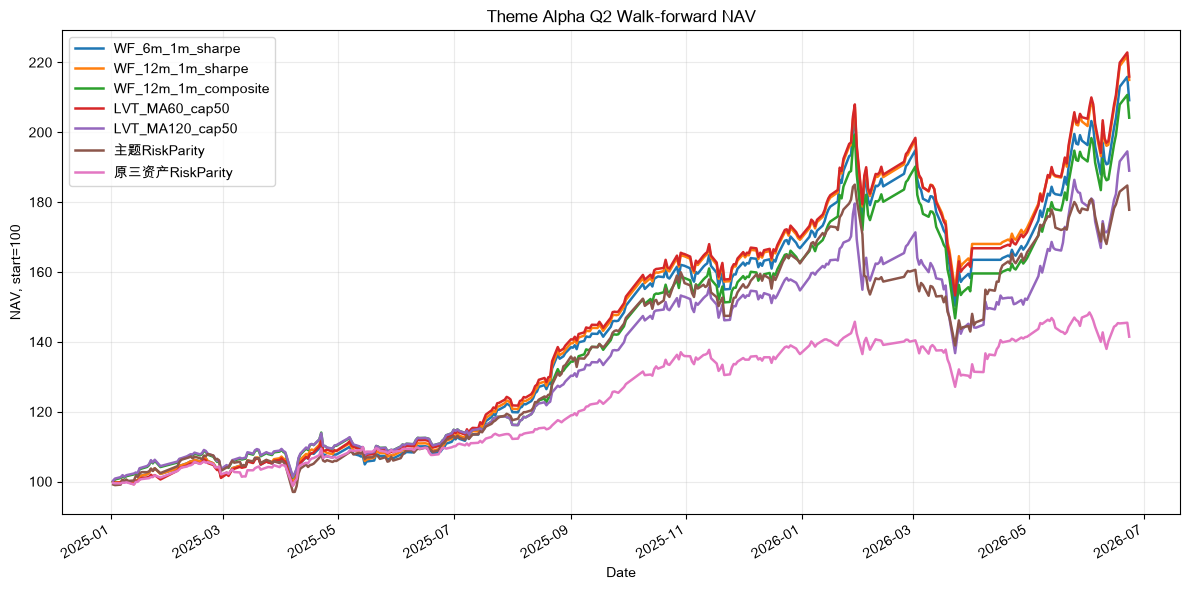

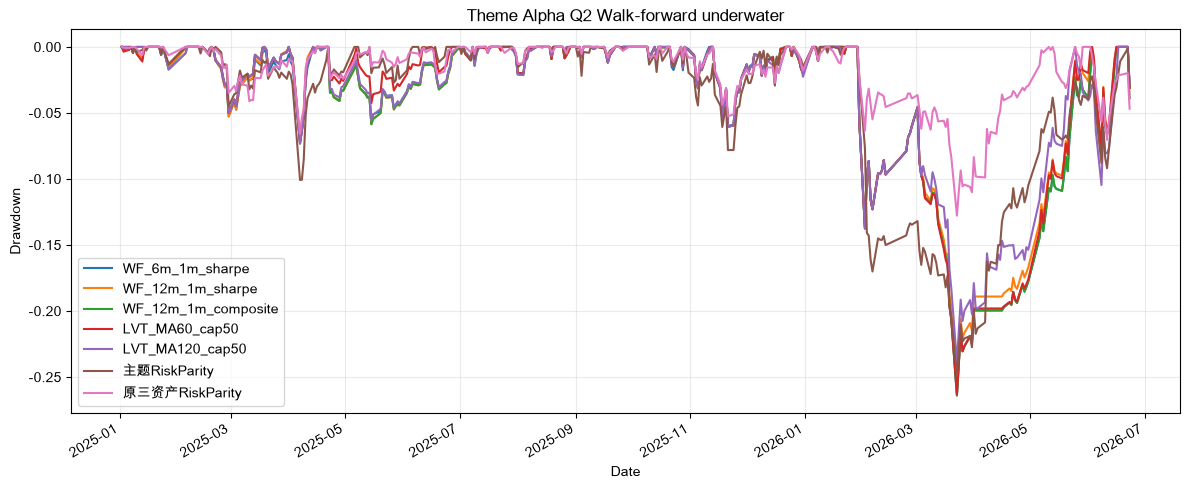

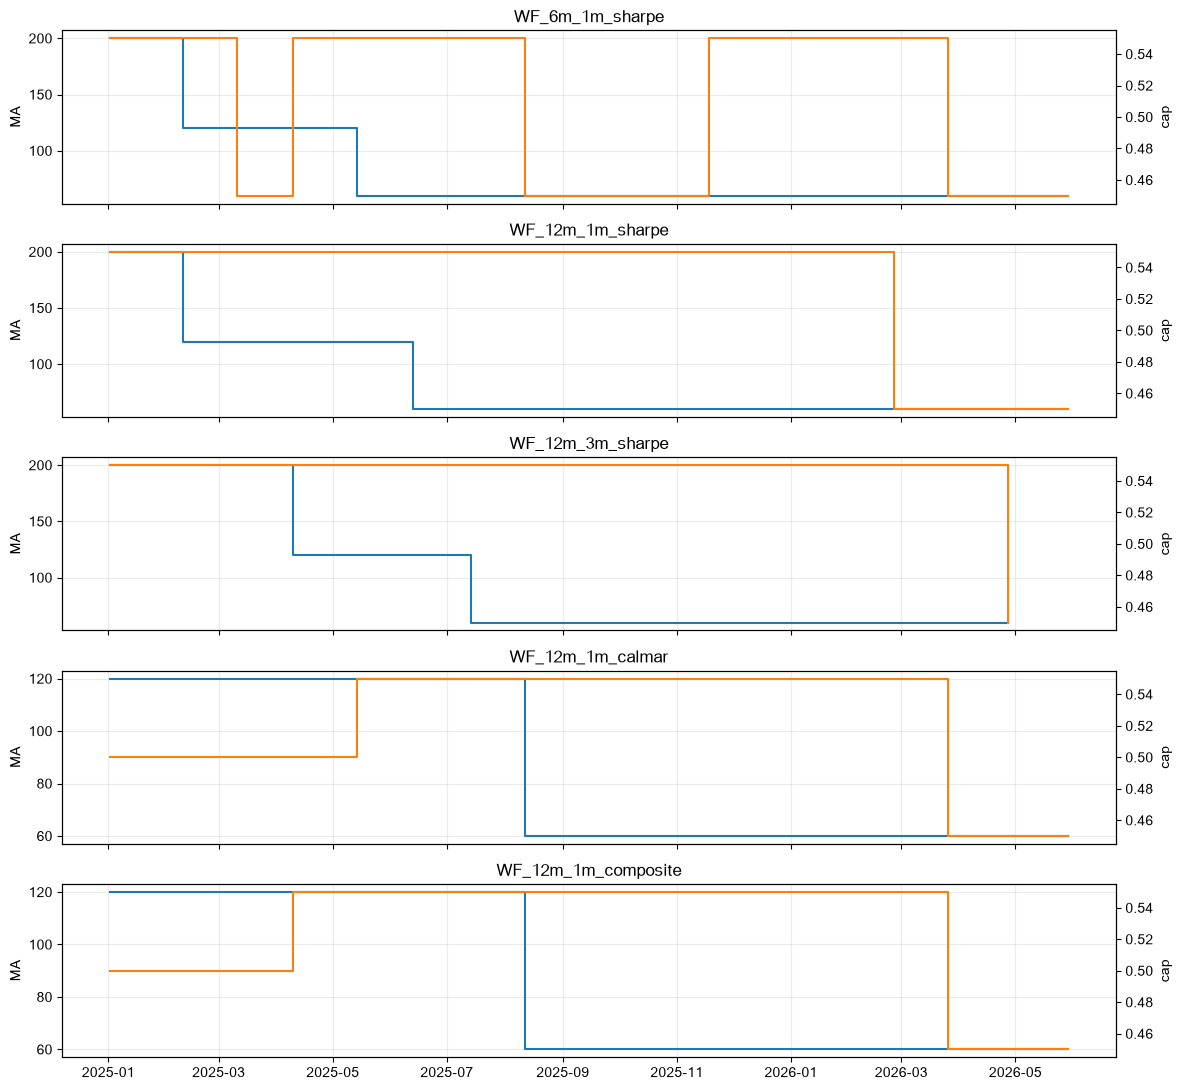

In [7]:
# Use 0 bps result for main chart.
_, chart_ports = evaluate_walkforward(cost_bps=0)
chart_names = ["WF_6m_1m_sharpe", "WF_12m_1m_sharpe", "WF_12m_1m_composite", "LVT_MA60_cap50", "LVT_MA120_cap50", "主题RiskParity", "原三资产RiskParity"]
ret_df = pd.DataFrame({name: chart_ports[name]["returns"].loc["2025-01-01":] for name in chart_names})
nav_df = ret_df.apply(lambda s: (1 + s).cumprod() * INITIAL_NAV)
underwater = nav_df.apply(lambda s: s / s.cummax() - 1.0)
nav_df.to_csv(OUTPUT_DIR / "nav_main_2025_to_date.csv", encoding="utf-8-sig")
underwater.to_csv(OUTPUT_DIR / "underwater_main_2025_to_date.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(12, 6))
nav_df.plot(ax=ax, linewidth=1.8)
ax.set_title("Theme Alpha Q2 Walk-forward NAV")
ax.set_ylabel("NAV, start=100")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nav_walkforward_2025_to_date.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
underwater.plot(ax=ax, linewidth=1.5)
ax.set_title("Theme Alpha Q2 Walk-forward underwater")
ax.set_ylabel("Drawdown")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "underwater_walkforward_2025_to_date.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(len(wf_specs), 1, figsize=(12, 2.2 * len(wf_specs)), sharex=True)
for ax, (name, *_rest) in zip(axes, wf_specs):
    sub = selection_history[selection_history["wf_name"] == name]
    ax.step(pd.to_datetime(sub["validate_start"]), sub["selected_ma"], where="post", label="MA")
    ax2 = ax.twinx()
    ax2.step(pd.to_datetime(sub["validate_start"]), sub["selected_cap"], color="tab:orange", where="post", label="cap")
    ax.set_title(name)
    ax.set_ylabel("MA")
    ax2.set_ylabel("cap")
    ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "selected_parameter_history.png", dpi=160, bbox_inches="tight")
plt.show()


## 7. Research Summary


In [8]:
summary_rows = []
for cost, df in wf_tables.items():
    summary_rows.append({
        "cost_bps": cost,
        "best_return": df["累计收益"].idxmax(),
        "best_sharpe": df["夏普"].idxmax(),
        "best_calmar": df["卡玛"].idxmax(),
        "wf_6m_1m_sharpe_return": df.loc["WF_6m_1m_sharpe", "累计收益"],
        "wf_12m_1m_sharpe_return": df.loc["WF_12m_1m_sharpe", "累计收益"],
        "static_ma60_cap50_return": df.loc["LVT_MA60_cap50", "累计收益"],
        "theme_rp_return": df.loc["主题RiskParity", "累计收益"],
        "baseline_return": df.loc["原三资产RiskParity", "累计收益"],
    })
research_summary = pd.DataFrame(summary_rows)
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(research_summary.round(4))


,cost_bps,best_return,best_sharpe,best_calmar,wf_6m_1m_sharpe_return,wf_12m_1m_sharpe_return,static_ma60_cap50_return,theme_rp_return,baseline_return
0,0,LVT_MA60_cap55,LVT_MA60_cap55,LVT_MA60_cap45,1.0918,1.1499,1.1595,0.7782,0.4148
1,10,LVT_MA60_cap55,LVT_MA60_cap55,LVT_MA60_cap45,1.0697,1.1279,1.1398,0.7724,0.4107
2,20,LVT_MA60_cap55,LVT_MA60_cap55,LVT_MA60_cap45,1.0478,1.1061,1.1203,0.7667,0.4066


## 8. Q5 Diagnostics补充

补充月度、水下、修复与核心对比表，避免只看总收益和 Sharpe。


In [9]:
# Q5-style monthly, underwater, and recovery diagnostics requested for review.

def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def monthly_diagnostics(name, r):
    m = r.dropna().resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0).dropna()
    wins = m[m > 0]
    losses = m[m < 0]
    return {
        "策略": name,
        "月数": len(m),
        "月胜率": (m > 0).mean() if len(m) else np.nan,
        "平均盈利月": wins.mean() if len(wins) else np.nan,
        "平均亏损月": losses.mean() if len(losses) else np.nan,
        "最差月": m.min() if len(m) else np.nan,
        "最好月": m.max() if len(m) else np.nan,
        "盈利因子": wins.sum() / abs(losses.sum()) if len(losses) and losses.sum() != 0 else np.nan,
    }


def drawdown_events(nav):
    dd = nav / nav.cummax() - 1.0
    events = []
    in_dd = False
    start = trough = peak = None
    trough_depth = 0.0
    for date, depth in dd.items():
        if depth < 0 and not in_dd:
            in_dd = True
            start = date
            peak = nav.loc[:date].idxmax()
            trough = date
            trough_depth = depth
        elif depth < 0 and in_dd:
            if depth < trough_depth:
                trough = date
                trough_depth = depth
        elif depth >= 0 and in_dd:
            events.append({
                "peak_date": peak,
                "start_date": start,
                "trough_date": trough,
                "recovery_date": date,
                "depth": trough_depth,
                "days_to_trough": (trough - start).days,
                "recovery_days": (date - start).days,
                "recovered": True,
            })
            in_dd = False
    if in_dd:
        last_date = dd.index[-1]
        events.append({
            "peak_date": peak,
            "start_date": start,
            "trough_date": trough,
            "recovery_date": pd.NaT,
            "depth": trough_depth,
            "days_to_trough": (trough - start).days,
            "recovery_days": np.nan,
            "unrecovered_days": (last_date - start).days,
            "recovered": False,
        })
    return pd.DataFrame(events)


def underwater_recovery_diagnostics(name, r):
    nav = nav_from_returns(r.dropna())
    dd = nav / nav.cummax() - 1.0
    events = drawdown_events(nav)
    recovered = events[events["recovered"]] if len(events) else pd.DataFrame()
    unresolved = events[~events["recovered"]] if len(events) else pd.DataFrame()
    return {
        "策略": name,
        "水下时间占比": (dd < 0).mean() if len(dd) else np.nan,
        "平均水下": dd[dd < 0].mean() if (dd < 0).any() else 0.0,
        "最长水下天数": events["recovery_days"].fillna(events.get("unrecovered_days", np.nan)).max() if len(events) else 0,
        "超过-10%天数": int((dd <= -0.10).sum()),
        "平均修复天数": recovered["recovery_days"].mean() if len(recovered) else np.nan,
        "最长修复天数": recovered["recovery_days"].max() if len(recovered) else np.nan,
        "未修复回撤": unresolved["depth"].iloc[-1] if len(unresolved) else 0.0,
        "未修复天数": unresolved["unrecovered_days"].iloc[-1] if len(unresolved) and "unrecovered_days" in unresolved else 0,
        "回撤事件数": len(events),
    }


def write_diagnostics(port_map, names, window_name, start, end=None, prefix=""):
    monthly_rows = []
    underwater_rows = []
    comparison_rows = []
    for name in names:
        port = port_map[name]
        r = slice_series(port["returns"], start, end)
        if len(r) < 20:
            continue
        monthly_rows.append(monthly_diagnostics(name, r))
        underwater_rows.append(underwater_recovery_diagnostics(name, r))
        comparison_rows.append(metrics_row(name, r, port["weights"], port["turnover"]))
    monthly_df = pd.DataFrame(monthly_rows).set_index("策略")
    underwater_df = pd.DataFrame(underwater_rows).set_index("策略")
    comparison_df = pd.DataFrame(comparison_rows).set_index("策略")
    stem = f"{prefix}_{window_name}" if prefix else window_name
    monthly_df.to_csv(OUTPUT_DIR / f"monthly_diagnostics_{stem}.csv", encoding="utf-8-sig")
    underwater_df.to_csv(OUTPUT_DIR / f"underwater_recovery_{stem}.csv", encoding="utf-8-sig")
    comparison_df.to_csv(OUTPUT_DIR / f"comparison_{stem}.csv", encoding="utf-8-sig")
    return monthly_df, underwater_df, comparison_df

q2_compare_ports = {
    "主题等权": benchmarks["主题等权"],
    "主题RiskParity": benchmarks["主题RiskParity"],
    "LVT_MA60_cap45": variant_ports["LVT_MA60_cap45"],
    "LVT_MA60_cap50": variant_ports["LVT_MA60_cap50"],
    "LVT_MA60_cap55": variant_ports["LVT_MA60_cap55"],
}
q2_compare_names = list(q2_compare_ports)

for window_name, (start, end) in windows.items():
    mdf, udf, cdf = write_diagnostics(q2_compare_ports, q2_compare_names, window_name, start, end, prefix="theme_lvt")
    print()
    print(f"Q2 diagnostics - {window_name}")
    display(cdf[["累计收益", "最大回撤", "夏普", "卡玛"]].round(4))
    display(mdf.round(4))
    display(udf.round(4))



Q2 diagnostics - 2025_only


,累计收益,最大回撤,夏普,卡玛
策略,,,,
主题等权,0.6744,-0.1396,3.2652,5.0878
主题RiskParity,0.6245,-0.1008,3.7143,6.5243
LVT_MA60_cap45,0.6938,-0.0695,4.4669,10.5267
LVT_MA60_cap50,0.6985,-0.0731,4.3913,10.0709
LVT_MA60_cap55,0.7176,-0.0685,4.5187,11.0498


,月数,月胜率,平均盈利月,平均亏损月,最差月,最好月,盈利因子
策略,,,,,,,
主题等权,12,0.7500,0.0630,-0.0077,-0.0167,0.1887,24.4359
主题RiskParity,12,0.9167,0.0474,-0.0168,-0.0168,0.1226,31.0720
LVT_MA60_cap45,12,0.8333,0.0557,-0.0041,-0.0052,0.1271,67.8699
LVT_MA60_cap50,12,0.8333,0.0564,-0.0058,-0.0076,0.1247,48.2917
LVT_MA60_cap55,12,0.8333,0.0576,-0.0063,-0.0076,0.1243,45.8061


,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
主题等权,0.7231,-0.0317,121.0,3,11.2174,121.0,-0.0107,2.0,24
主题RiskParity,0.6777,-0.0181,57.0,2,7.6562,57.0,-0.0152,2.0,33
LVT_MA60_cap45,0.6777,-0.0149,38.0,0,7.3636,38.0,-0.0198,2.0,34
LVT_MA60_cap50,0.6736,-0.0159,50.0,0,7.1176,50.0,-0.0198,2.0,35
LVT_MA60_cap55,0.6860,-0.0168,65.0,0,7.4848,65.0,-0.0198,2.0,34



Q2 diagnostics - 2026_ytd


...

,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
主题等权,0.8739,-0.1387,144.0,63,1.6667,2.0,-0.2794,144.0,4
主题RiskParity,0.8649,-0.1131,144.0,56,1.3333,2.0,-0.2489,144.0,4
LVT_MA60_cap45,0.8198,-0.1136,124.0,45,35.5000,124.0,-0.0310,0.0,5
LVT_MA60_cap50,0.8198,-0.1178,124.0,46,35.5000,124.0,-0.0310,0.0,5
LVT_MA60_cap55,0.8198,-0.1177,124.0,48,35.5000,124.0,-0.0310,0.0,5



Q2 diagnostics - 2025_to_date


,累计收益,最大回撤,夏普,卡玛
策略,,,,
主题等权,0.8523,-0.2794,2.1037,1.9784
主题RiskParity,0.7782,-0.2489,2.2960,2.0421
LVT_MA60_cap45,1.1528,-0.2521,3.0797,2.8903
LVT_MA60_cap50,1.1595,-0.2630,3.0550,2.7856
LVT_MA60_cap55,1.1838,-0.2639,3.1200,2.8280


,月数,月胜率,平均盈利月,平均亏损月,最差月,最好月,盈利因子
策略,,,,,,,
主题等权,18,0.7222,0.0735,-0.0546,-0.1355,0.1887,3.5046
主题RiskParity,18,0.7778,0.0620,-0.0599,-0.1139,0.1585,3.6195
LVT_MA60_cap45,18,0.7778,0.0720,-0.0440,-0.1650,0.1766,5.7307
LVT_MA60_cap50,18,0.7778,0.0735,-0.0473,-0.1743,0.1924,5.4402
LVT_MA60_cap55,18,0.7778,0.0743,-0.0472,-0.1729,0.1886,5.5091


,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
主题等权,0.7705,-0.0699,144.0,66,10.0000,121.0,-0.2794,144.0,28
主题RiskParity,0.7365,-0.0532,144.0,58,7.1111,57.0,-0.2489,144.0,37
LVT_MA60_cap45,0.7252,-0.0500,124.0,45,10.3421,124.0,-0.0310,0.0,39
LVT_MA60_cap50,0.7224,-0.0522,124.0,46,10.0513,124.0,-0.0310,0.0,40
LVT_MA60_cap55,0.7309,-0.0523,124.0,48,10.4474,124.0,-0.0310,0.0,39
